# Week 1, Part 02: Data Exploration: Provenance, Shape, and Quality

<sub>[Previous: Defining the Problem and Acquiring the Data](week1_01_problem_and_acquisition.ipynb) &nbsp;&middot;&nbsp; [Next: Exploratory Data Analysis and Visualization](week1_03_eda_and_visualization.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Before trusting anything, we do the boring but essential work: look at the shape and types, find the holes, write down what each field means, and name the biases we know live in birth-certificate data. This is the part that decides whether everything downstream is real.

### Contents

1. [Shape, types, and memory](#shape)
2. [Missingness](#missing)
3. [A field dictionary](#dictionary)
4. [Known biases](#biases)
5. [Group sizes](#groups)

### Setup

A short, documented setup so the rest of the notebook reads cleanly. First the imports and display options. `scipy` is here because we run real hypothesis tests later, and we fix a random seed so every `df.sample()` below is reproducible.

In [1]:
# Setup. Week 1 is acquisition + exploration + EDA, so we load the RAW exploration table:
# the 17 pre-delivery birth-certificate fields we gathered, with their original values untouched.
# (No engineered features, no modeling columns yet. Those come in later weeks.) This table is built
# from the COMPLETE NBER public-use files for 2018-2024, restricted to singletons. Every number below
# is computed live from it. scipy is here for the hypothesis tests we run as we go, and we fix a seed
# so every df.sample() is reproducible.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
RNG = 7  # fixed seed so every df.sample() below is reproducible

Load the raw exploration table once. It holds the 17 pre-delivery certificate fields we gathered this week, built from the complete 2018-2024 public-use files (singletons only), plus readable label maps for the coded fields and the published national birth totals we will validate our counts against.

In [2]:
DATA = Path("..") / "data" / "interim" / "natality_exploration_2019_2024.parquet"
df = pd.read_parquet(DATA)  # ALL U.S. singleton births 2018-2024, raw pre-delivery fields only

# Human-readable label maps for the coded NCHS fields.
EDU = {1: "<8th grade", 2: "9-12, no diploma", 3: "HS grad/GED", 4: "Some college",
       5: "Associate", 6: "Bachelor", 7: "Master", 8: "Doctorate/Prof"}
PAY = {1: "Private", 2: "Medicaid", 3: "Self-pay", 4: "Indian Health Svc", 5: "CHAMPUS/TRICARE",
       6: "Other govt", 8: "Other"}
RACE_ORDER = ["NH White", "NH Asian", "Hispanic", "NH Multiracial", "NH NHOPI", "NH AIAN", "NH Black"]
# Published total U.S. births (NCHS final; 2024 provisional). Singletons are about 96.8% of births.
PUBLISHED_BIRTHS = {2018: 3791712, 2019: 3747540, 2020: 3613647, 2021: 3664292, 2022: 3667758,
                    2023: 3596017, 2024: 3600000}

A colorblind-safe palette (the Okabe-Ito set), reused on every figure so the series looks like one piece. We give the four largest race groups distinct colors and leave the rest grey to keep attention where the data are most reliable.

In [3]:
PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999",
           "ink": "#1a1a2e"}
RACE_COLOR = {r: PALETTE["grey"] for r in RACE_ORDER}
RACE_COLOR.update({"NH White": PALETTE["blue"], "NH Black": PALETTE["red"],
                   "Hispanic": PALETTE["green"], "NH Asian": PALETTE["orange"]})

Matplotlib house style, plus a tiny `style()` helper so every static figure gets a takeaway-as-title and labelled axes without repeating boilerplate.

In [4]:
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    return ax

Marquee charts also get an interactive Plotly companion, so `ptmpl()` gives those figures the same dark-text, low-clutter house style.

In [5]:
pio.renderers.default = "notebook_connected"  # small files; interactive in Jupyter / nbviewer

def ptmpl(fig, title, xtitle, ytitle, height=440):
    fig.update_layout(
        title=dict(text=title, x=0.02, font=dict(size=16, color=PALETTE["ink"])),
        xaxis_title=xtitle, yaxis_title=ytitle, plot_bgcolor="white", paper_bgcolor="white",
        font=dict(family="Inter, system-ui, sans-serif", size=13, color=PALETTE["ink"]),
        margin=dict(l=60, r=30, t=60, b=50), height=height,
        legend=dict(orientation="h", yanchor="bottom", y=1.03, x=0, font=dict(color=PALETTE["ink"])))
    fig.update_xaxes(showgrid=False, linecolor="#cccccc")
    fig.update_yaxes(showgrid=True, gridcolor="#ECECEC", zeroline=False)
    return fig

Finally, the 2 helpers we lean on most. `rate_by()` returns the preterm rate and count for any grouping column, and it is the workhorse of the entire EDA. `risk_ratio_ci()` goes 1 step further for binary flags: it returns the risk ratio (flag=1 vs flag=0) with a 95% log-normal confidence interval, so we can report an effect size and its uncertainty together, not just a p-value. Both are worth reading once.

In [6]:
def rate_by(frame, col, dropna_target=True):
    """Preterm rate (%) and count for any grouping column. The workhorse of the whole EDA."""
    d = frame.dropna(subset=["preterm"]) if dropna_target else frame
    g = d.groupby(col)["preterm"].agg(rate="mean", n="size")
    g["rate"] = g["rate"] * 100
    return g

def risk_ratio_ci(frame, flag_col, target="preterm"):
    """Risk ratio (flag=1 vs flag=0) with a 95% log-normal CI. Returns (rr, lo, hi, r1, r0)."""
    d = frame.dropna(subset=[target, flag_col])
    g = d.groupby(flag_col)[target].agg(["mean", "sum", "size"])
    r1, r0 = g.loc[1.0, "mean"], g.loc[0.0, "mean"]
    a, n1 = g.loc[1.0, "sum"], g.loc[1.0, "size"]
    c, n0 = g.loc[0.0, "sum"], g.loc[0.0, "size"]
    rr = r1 / r0
    se = np.sqrt(1/a - 1/n1 + 1/c - 1/n0)
    return rr, rr*np.exp(-1.96*se), rr*np.exp(1.96*se), r1*100, r0*100

### First, a look at the raw material

Each notebook stands on its own, so we start the way a real analysis session does: load the table and look at a handful of actual rows. One record is one singleton birth.

In [7]:
df.sample(5, random_state=RNG)

,birth_year,mager,meduc,bmi,cig_0,priorlive,priordead,married,rf_pdiab,rf_phype,rf_ppterm,rf_cesar,wic,first_trimester_care,pay,mother_race_ethnicity,preterm
19117181,2023,26,6.0,26.600000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,Hispanic,0.0
19115281,2023,36,7.0,24.000000,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,NH White,0.0
24082594,2024,28,4.0,23.200001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,NH Multiracial,0.0
3195108,2018,30,3.0,25.700001,0.0,4.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,Hispanic,0.0
6895695,2019,30,6.0,19.000000,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,NH White,0.0


<a id="shape"></a>
## Shape, types, and memory

The first mechanical inspection any analysis owes itself: how many rows and columns, what types, and how much memory. I also want a compact, `info()`-style per-field summary so I can see at a glance which fields are present and how many distinct values each takes.

In [8]:
print('Shape (rows, fields):', df.shape)
print('Memory             :', f'{df.memory_usage(deep=True).sum()/1e6:.0f} MB')
print('Dtype counts:'); print(df.dtypes.value_counts())

Shape (rows, fields): (24941021, 17)
Memory             : 4708 MB
Dtype counts:
float64    14
int32       1
int64       1
object      1
Name: count, dtype: int64


In [9]:
pd.DataFrame({'dtype': df.dtypes.astype(str), 'non_null': df.notna().sum(),
              'pct_present': (df.notna().mean()*100).round(1),
              'n_unique': df.nunique(dropna=True)})

,dtype,non_null,pct_present,n_unique
birth_year,int32,24941021,100.0,7
mager,int64,24941021,100.0,39
meduc,float64,24548125,98.4,8
bmi,float64,24941021,100.0,1027
cig_0,float64,24829248,99.6,91
priorlive,float64,24893924,99.8,24
priordead,float64,24869460,99.7,20
married,float64,22058371,88.4,2
rf_pdiab,float64,24905769,99.9,2
rf_phype,float64,24905769,99.9,2


17 fields and about 25 million rows, all numeric except the race/ethnicity label. Even at the full national scale this slim 17-column projection is only a few gigabytes in memory, so we can explore it interactively in pandas without reaching for chunking or Spark. That is the payoff of projecting to just the fields we need before pooling the years. Nothing here is surprising yet, which is exactly what we want from a first look: surprises this early usually mean a parsing bug, not a discovery.

<a id="missing"></a>
## Missingness

Missingness is never random noise in administrative data, so we map it before trusting any field. Let me compute the missing share per field and plot only the ones that actually have gaps.

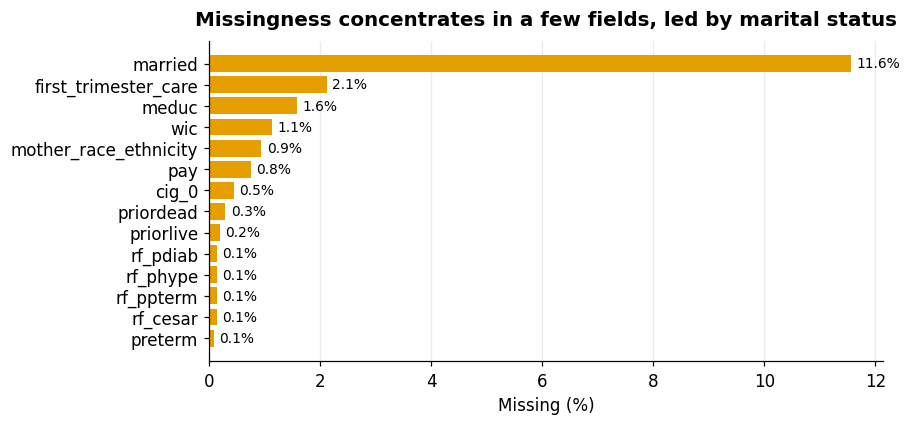

In [10]:
miss = (df.isna().mean()*100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.barh(miss.index[::-1], miss.values[::-1], color=PALETTE['orange'])
for i, v in enumerate(miss.values[::-1]): ax.text(v+0.1, i, f'{v:.1f}%', va='center', fontsize=9)
style(ax, 'Missingness concentrates in a few fields, led by marital status', 'Missing (%)', '')
ax.grid(axis='y'); plt.tight_layout(); plt.show()

The big one is marital status (`married`), blank for about 12% of rows. That is not noise: some reporting areas historically did not collect it the same way, so it is *missing not at random* and correlated with place. Everything else sits under 2%. The lesson we carry into the modeling weeks is to handle missingness per-field and treat the fact that something is missing as possibly informative, rather than blindly dropping or mean-filling. For this week's descriptive work I simply exclude missing values from each statistic and say so.

**Why I call marital status missing not at random (MNAR).** A missing value is only harmless if it is missing completely at random: unrelated to anything we care about, including time. Marital status is not. The public-use files carry no geography, but the reporting-area story is well documented: some jurisdictions historically collected and reported marital status differently (a few once inferred it rather than asking directly), so whether the field is blank depends on *where* and *when* the birth was registered, which is itself correlated with the population and the outcome. If the gaps were purely random loss, the missing share would sit roughly flat near a single value across years, not follow a direction. Let me split the missing share by year and look at its shape, because a share that trends over time is better explained by how collection changed than by random loss.

In [11]:
# WHY marital status is missing not at random: split its missing share by year.
mar_by_year = (df.assign(missing=df['married'].isna())
                 .groupby('birth_year')['missing'].mean().mul(100).round(2))
print("Marital-status missing share by year (%):")
print(mar_by_year.to_string())
print(f"\nRange across years: {mar_by_year.max():.1f}% (2018) down to {mar_by_year.min():.1f}% (2024). "
      "Declines steadily by year (about 1 point), so not flat: consistent with reporting-area "
      "collection differences converging over time (still not missing-at-random).")

Marital-status missing share by year (%):
birth_year
2018    12.03
2019    11.93
2020    11.66
2021    11.51
2022    11.47
2023    11.16
2024    11.11

Range across years: 12.0% (2018) down to 11.1% (2024). Declines steadily by year (about 1 point), so not flat: consistent with reporting-area collection differences converging over time (still not missing-at-random).


The missing share is not flat: it declines steadily and monotonically, from about 12.0% in 2018 to about 11.1% in 2024, roughly a 1-point slide over the window. That steady decline is not the erratic year-to-year noise you would see from random loss; a monotonic trend is better explained by reporting areas gradually converging on more consistent marital-status collection over time. The core point stands either way: the blanks are tied to when (and where) the birth was registered, so they are informative rather than missing completely at random. In the modeling weeks (PLANNED) I therefore intend to treat the fact that marital status is missing as possibly informative in its own right, likely with an explicit missing-indicator, rather than mean-fill it and pretend the gap is neutral. This stays associational: the trend is evidence about how the field was recorded, not a claim about any mother.

<a id="dictionary"></a>
## A field dictionary

Before relating fields to the outcome, we want a clear record of what each one means and where on the certificate it comes from. One column matters enormously for the modeling weeks: the *timing*. A field is only a fair predictor if it is known *before* delivery. I also record the *valid range* and the *sentinel / unknown code* for each field, because NCHS encodes not-stated as an in-range-looking number (for example BMI 99.9), and knowing the exact code up front is what lets the pipeline null it instead of averaging it in. These 2 columns are documentation drawn from the ingest schema, not values computed here.

| Field | Meaning | Source on the certificate | Valid range | Sentinel / unknown code | Known before delivery? |
|---|---|---|---|---|---|
| `birth_year` | Year of birth, 2018-2024 | Registration | 2018-2024 | none | Context |
| `mager` | Maternal age (years) | Mother's reported age | 12-50 | none (always present) | Yes |
| `meduc` | Education, 1 (<8th grade) to 8 (doctorate) | Mother's education | 1-8 | 9 | Yes |
| `bmi` | Pre-pregnancy body mass index | Height and pre-pregnancy weight (worksheet) | ~13-69.9 | 99.9 | Yes |
| `cig_0` | Cigarettes/day before pregnancy | Tobacco-use fields | 0-98 | 99 | Yes |
| `priorlive` / `priordead` | Prior live births / prior deaths | Pregnancy history | 0-98 | 99 | Yes |
| `married` | Marital status (1 = married), raw `dmar` | Marital status | 1-2 | 9 | Yes |
| `rf_pdiab` `rf_phype` `rf_ppterm` `rf_cesar` | Pre-pregnancy diabetes, hypertension, prior preterm, prior cesarean | Risk-factor checkboxes | Y / N | U (unknown) | Yes |
| `wic` | WIC nutrition-program participant | WIC field | recoded 0/1 | U (unknown) upstream | Yes (an SES proxy) |
| `first_trimester_care` | Prenatal care began in trimester 1 | Month care began | recoded 0/1 | 99 on raw `precare` upstream | Yes |
| `pay` | Principal payment source (Medicaid, private, ...) | Source of payment | 1-8 | 9 | Yes (an SES proxy) |
| `mother_race_ethnicity` | Bridged race/ethnicity | Mother's race and Hispanic origin | 7 labels | mapped upstream | A marker, never a cause |
| `preterm` | **Target**: born before 37 weeks | Derived from the obstetric gestational estimate | 0/1 (derived) | 99 on raw gestation upstream | The outcome |

A few notes on that sentinel column. `wic` and `first_trimester_care` reach this table already recoded to a clean 0/1, and `preterm` is the derived 0/1 target, so the codes shown for them are the ones that were resolved *upstream* in ingest (the raw `precare` month-care field uses 99, the raw gestation field uses 99) rather than codes still present here. The Y/N risk flags use the string `U` for unknown. The point of writing these down is that the sentinels for `bmi` (99.9) and `cig_0` (99) sit right at the top of an otherwise plausible numeric range, so the EDA has to hunt them explicitly (notebook 03 does exactly that) rather than assume a describe() max is a real measurement.

We deliberately gathered only fields known before delivery, plus the target. The tempting at-delivery fields (birthweight, Apgar, NICU) are not in this table on purpose; designing the tested gate that keeps them out is a planned task for the feature-engineering week.

<a id="biases"></a>
## Known biases

Birth certificates are a gold standard but they are not flawless. Three caveats we carry forward:

1. **Race and ethnicity misclassification.** Self-reported race is highly accurate for White, Black, and Hispanic groups but materially less so for [American Indian / Alaska Native and NHOPI](https://www.cdc.gov/nchs/hus/sources-definitions/race.html), where misclassification can understate rates. Those groups are also the smallest here, so we read their estimates with extra caution.
2. **Self-reported anthropometrics.** NCHS quality studies explicitly [did not assess the maternal worksheet's height and weight](https://www.cdc.gov/nchs/data/nvsr/nvsr65/nvsr65_06.pdf), so `bmi` is the least-audited clinical field. We expect to find sentinel codes lurking in it.
3. **Checkbox underreporting.** Risk-factor checkboxes (`rf_*`) are known to undercount true prevalence, which biases their measured association toward zero. So any weak association we find from them is really a floor.

**A note on the missing birth identifier (no UID).** The public-use file carries no birth identifier, no way to tell one record from another beyond its field values. A direct consequence is that with coarse categorical features (a handful of age bins, education codes, yes/no flags) some records will share an identical feature fingerprint simply because 2 real, distinct births looked the same on the parts of the certificate we kept. That is expected, not a corruption: these are not duplicated rows, they are separate births that happen to be indistinguishable through this narrow 17-field window. Because there is no identifier, a model cannot use these matches to memorize any individual; there is no individual to memorize. This is a known property of administrative microdata, and we carry it forward honestly rather than 'de-duplicating' away real births. (I deliberately quote no specific duplicate percentage; any such figure would be an artifact of which features you happen to keep, not a property of the data.)

<a id="groups"></a>
## Group sizes

The misclassification caveat above is abstract until we see the actual group sizes. Let me list them, smallest first, because the smallest groups are exactly where both misclassification and noise hit hardest.

In [12]:
small = df.dropna(subset=['preterm']).groupby('mother_race_ethnicity').size().sort_values()
print('Sample size by race/ethnicity group (smallest carry the most uncertainty):')
print(small.to_string())

Sample size by race/ethnicity group (smallest carry the most uncertainty):
mother_race_ethnicity
NH NHOPI             67182
NH AIAN             179698
NH Multiracial      587517
NH Asian           1535378
NH Black           3471014
Hispanic           6274954
NH White          12575254


**Takeaway.** Even in the full data NH NHOPI and NH AIAN are the smallest groups (roughly 67k and 180k rows, against millions for the large groups), so we trust the NH White, NH Black, Hispanic, and NH Asian estimates most and caveat the small ones wherever they appear.

**One external cross-check that the ingest did the right thing.** Everything above audits the data against itself. The stronger test is whether it reproduces the outside world: published NVSS reporting has a well-known per-race ordering of preterm rates. If our full-data rates land in that same order and near those magnitudes, that is external evidence the ingest pipeline did its job correctly end to end: de-sentinelling the not-stated codes, deriving the preterm target from the obstetric gestation, mapping race/ethnicity, and applying the singleton filter. A silent bug in any of those steps would knock the ordering out of line, so this is validation, not just description.

In [13]:
rr = rate_by(df, 'mother_race_ethnicity').reindex(RACE_ORDER).dropna()
print("Per-race preterm rate (%), our full data (validates the ingest against published NVSS ordering):")
print(rr['rate'].round(2).to_string())
print(f"\nOrdering check: NH White lowest ({rr.loc['NH White','rate']:.2f}%), "
      f"NH Black highest ({rr.loc['NH Black','rate']:.2f}%) -> matches published NVSS pattern.")

Per-race preterm rate (%), our full data (validates the ingest against published NVSS ordering):
mother_race_ethnicity
NH White           7.54
NH Asian           7.58
Hispanic           8.64
NH Multiracial     8.95
NH NHOPI          10.80
NH AIAN           10.68
NH Black          12.28

Ordering check: NH White lowest (7.54%), NH Black highest (12.28%) -> matches published NVSS pattern.


The rates reproduce the published pattern: NH White lowest, NH Black highest, with the other groups ranged between, and all near the magnitudes NVSS reports. That is the reassurance we wanted that de-sentinelling, target construction, race mapping, and the singleton filter all behaved. The 2 smallest groups (NH AIAN and NH NHOPI) still carry the misclassification caveat from the biases section, so their exact values are the ones I lean on least. And the framing that governs the whole project holds here too: **race is a marker of exposure to racism and structural barriers, never a biological cause** of preterm birth. With provenance settled, the shape understood, the holes mapped, the biases named, and the ingest externally validated, we have earned the right to let the data actually talk. That is the next notebook.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
